In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("../../datasets/heart_final_cleaned.csv")
df = df.dropna().reset_index(drop=True)

X = df.drop("target", axis=1).values.astype(float)
y = df["target"].values.astype(int)

print("Dataset Shape:", df.shape)
print("\nTarget Distribution:")
print(df["target"].value_counts())

Dataset Shape: (302, 14)

Target Distribution:
target
1    164
0    138
Name: count, dtype: int64


In [3]:
def split_data(X, y, test_size=0.2, seed=42):

    rng = np.random.default_rng(seed)

    train_idx, test_idx = [], []

    for cls in np.unique(y):

        indices = np.where(y == cls)[0]
        rng.shuffle(indices)

        split = int(len(indices) * (1 - test_size))

        train_idx.extend(indices[:split])
        test_idx.extend(indices[split:])

    train_idx = np.array(train_idx)
    test_idx = np.array(test_idx)

    rng.shuffle(train_idx)
    rng.shuffle(test_idx)

    return (X[train_idx], X[test_idx],
            y[train_idx], y[test_idx])


X_train, X_test, y_train, y_test = split_data(X, y)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (241, 13)
Testing Data: (61, 13)


In [4]:
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)

std[std == 0] = 1

X_train_scaled = (X_train - mean) / std
X_test_scaled = (X_test - mean) / std

print("Training Features Scaled")
print("Testing Features Scaled")

Training Features Scaled
Testing Features Scaled


In [5]:
y_train_svm = np.where(y_train == 1, 1, -1)
y_test_svm = np.where(y_test == 1, 1, -1)

print("SVM Target Labels:", np.unique(y_train_svm))

SVM Target Labels: [-1  1]


In [6]:
def train_svm(X, y, learning_rate=0.001, epochs=3000, C=1):

    n_samples, n_features = X.shape

    weights = np.zeros(n_features)
    bias = 0

    losses = []

    for epoch in range(epochs):

        margins = y * (X @ weights + bias)

        violations = margins < 1

        dw = weights - C * (X[violations].T @ y[violations]) / n_samples

        db = -C * np.sum(y[violations]) / n_samples

        weights -= learning_rate * dw
        bias -= learning_rate * db

        current_margins = y * (X @ weights + bias)

        hinge_loss = np.maximum(0, 1 - current_margins).mean()

        loss = 0.5 * np.sum(weights ** 2) + C * hinge_loss

        losses.append(loss)

    return weights, bias, losses


weights, bias, losses = train_svm(
    X_train_scaled,
    y_train_svm,
    learning_rate=0.001,
    epochs=3000,
    C=1
)

print("SVM Training Completed")
print("Weights:", weights)
print("Bias:", bias)

SVM Training Completed
Weights: [-0.04080742 -0.10377528  0.1947169  -0.05387171 -0.02603581 -0.00486837
  0.0451945   0.1964527  -0.17676305 -0.17743424  0.13205683 -0.2158854
 -0.18558043]
Bias: 0.2119460580912916


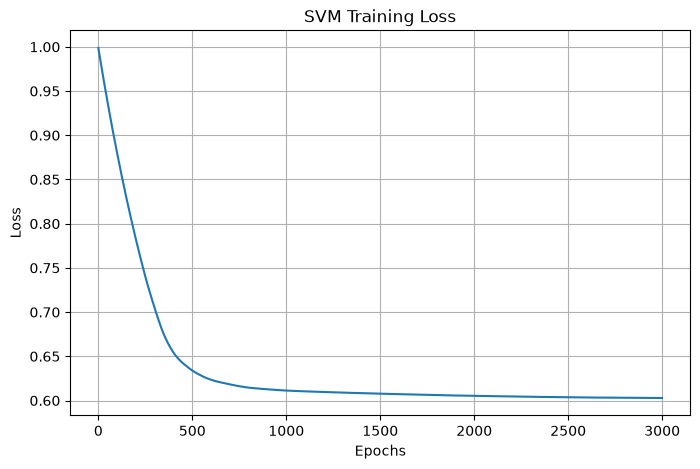

In [7]:
plt.figure(figsize=(8, 5))

plt.plot(losses)

plt.title("SVM Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.grid()
plt.show()

In [8]:
def predict_svm(X, weights, bias):

    scores = X @ weights + bias

    return np.where(scores >= 0, 1, -1)


y_pred_svm = predict_svm(
    X_test_scaled,
    weights,
    bias
)

print("Actual Labels:   ", y_test_svm[:10])
print("Predicted Labels:", y_pred_svm[:10])

Actual Labels:    [-1  1 -1  1 -1 -1  1  1  1  1]
Predicted Labels: [1 1 1 1 1 1 1 1 1 1]


In [9]:
correct = 0

for actual, predicted in zip(y_test_svm, y_pred_svm):

    if actual == predicted:
        correct += 1

accuracy = correct / len(y_test_svm) * 100

print("Total Predictions:", len(y_test_svm))
print("Correct Predictions:", correct)
print("Incorrect Predictions:", len(y_test_svm) - correct)
print("SVM Accuracy:", round(accuracy, 2), "%")

Total Predictions: 61
Correct Predictions: 51
Incorrect Predictions: 10
SVM Accuracy: 83.61 %


In [10]:
decision_scores = X_test_scaled @ weights + bias

hinge_losses = np.maximum(
    0,
    1 - y_test_svm * decision_scores
)

print("Average Test Hinge Loss:", round(np.mean(hinge_losses), 4))
print("Margin Violations:", np.sum(hinge_losses > 0))

Average Test Hinge Loss: 0.4975
Margin Violations: 42


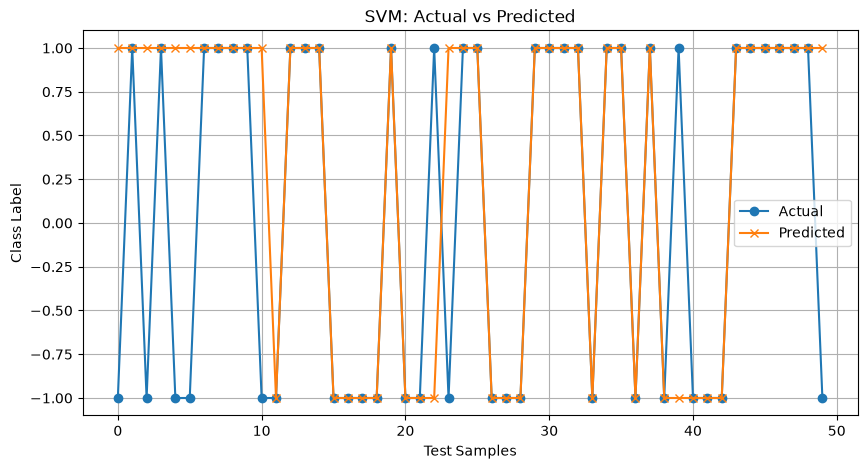

In [11]:
plt.figure(figsize=(10, 5))

plt.plot(y_test_svm[:50], label="Actual", marker="o")
plt.plot(y_pred_svm[:50], label="Predicted", marker="x")

plt.title("SVM: Actual vs Predicted")
plt.xlabel("Test Samples")
plt.ylabel("Class Label")

plt.legend()
plt.grid()
plt.show()

## Conclusion

In this task, a Support Vector Machine classifier was implemented
from scratch without using scikit-learn.

The model used gradient descent to optimize the hyperplane and
soft margin classification to handle data points that violate
the ideal margin.

Feature scaling was applied before training, and the model was
evaluated using manually calculated accuracy and hinge loss.

The implementation demonstrates the working principles of
SVM, maximum-margin classification, regularization, and
soft-margin optimization.